Basic Information
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   BMI     10 non-null     float64
 1   Age     10 non-null     int64  
 2   Sugar   10 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 372.0 bytes
None


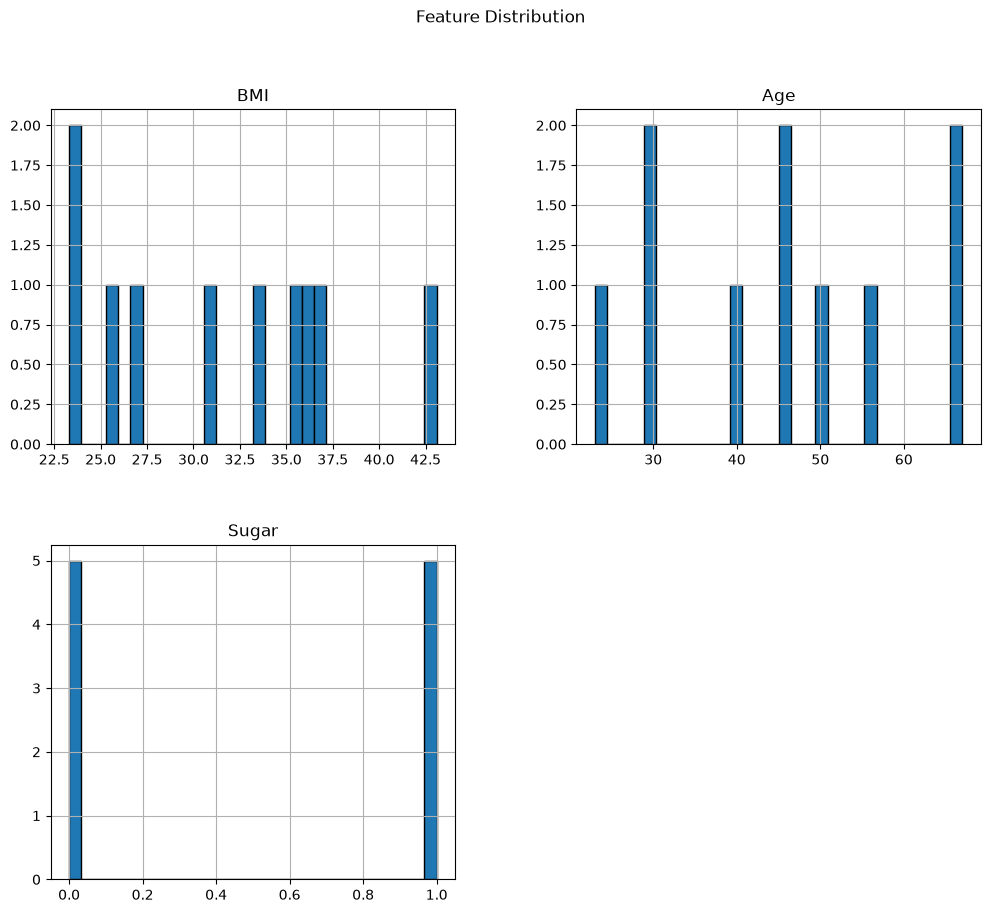

Accuracy: 1.00
Prediction for the new data point [[43.6 40. ]]: 1


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from math import sqrt
from collections import Counter
data={
    "BMI": [33.6, 26.6, 23.4, 43.1, 35.3, 35.9, 36.7, 25.7, 23.3, 31.0],
    "Age":[50,30,40,67,23,67,45,46,29,56],
    "Sugar":[1,0,0,0,1,1,1,0,0,1]
}
df=pd.DataFrame(data)
df
print("Basic Information")
print(df.info())

df.hist(figsize=(12,10),bins=30,edgecolor='black')
plt.suptitle("Feature Distribution")
plt.show()

class KNN:

    def __init__(self, k=3):
        self.k = k

    def fit(self, X_train, y_train):
        self.X_train = X_train
        self.y_train = y_train

    def calculate_euclidean(self, sample1, sample2):
        distance = np.sqrt(np.sum((sample1 - sample2) ** 2))
        return distance

    def nearest_neighbors(self, test_sample):
        distances = [
            (self.y_train[i],
             self.calculate_euclidean(self.X_train[i], test_sample))
            for i in range(len(self.X_train))
        ]
        distances.sort(key=lambda x: x[1])
        neighbors = [distances[i][0] for i in range(self.k)]
        return neighbors

    def predict(self, test_set):
        predictions = []
        for test_sample in test_set:
            neighbors = self.nearest_neighbors(test_sample)
            prediction = Counter(neighbors).most_common(1)[0][0]
            predictions.append(prediction)
        return predictions


X = df.drop(columns='Sugar').values
y = df['Sugar'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

knn = KNN(k=3)

knn.fit(X_train, y_train)

predictions = knn.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy: {accuracy:.2f}")

new_data = np.array([[43.6,40]])

new_data_normalized = scaler.transform(new_data)

new_prediction = knn.predict(new_data_normalized)

print(f"Prediction for the new data point {new_data}: {new_prediction[0]}")